# Regresión por kernels: implementación, sobreajuste y validación cruzada LOOCV
**Práctica de clase | Python, NumPy y Matplotlib**

**Objetivos:** (1) construir el estimador Nadaraya–Watson desde cero; (2) comprender los pesos y el *broadcasting*; (3) estudiar el ancho de banda $h$ y el sobreajuste; (4) seleccionar $h$ mediante validación cruzada dejando uno fuera (*leave-one-out*, LOOCV); (5) interpretar los grados de libertad efectivos.

No utilizaremos bibliotecas de regresión ni de validación cruzada. Todas las funciones se programan explícitamente.

## 1. Fundamento matemático
Disponemos de observaciones $(x_i,y_i)$, $i=1,\ldots,n$, generadas, por ejemplo, por
$$y_i=f(x_i)+\varepsilon_i.$$
El estimador de **Nadaraya–Watson** predice:
$$
\boxed{\hat f_h(x)=\frac{\sum_{i=1}^{n}K_h(x-x_i)y_i}{\sum_{i=1}^{n}K_h(x-x_i)}}.
$$
Usamos el kernel gaussiano sin constante multiplicativa (se cancela en el cociente):
$$K_h(u)=\exp\left(-\frac{u^2}{2h^2}\right),\quad h>0.$$
La predicción es una media ponderada con pesos normalizados
$$\alpha_i(x)=\frac{K_h(x-x_i)}{\sum_j K_h(x-x_j)},\qquad \sum_i\alpha_i(x)=1.$$
**Intuición:** un $h$ pequeño da importancia a vecinos muy cercanos; un $h$ grande promedia regiones amplias.

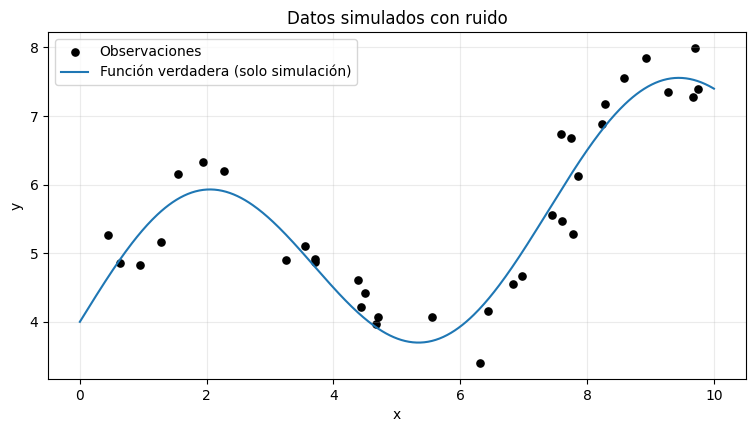

Número de observaciones: 35


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 35
x = np.sort(rng.uniform(0, 10, n))

def f_verdadera(x):
    return 4 + 1.5 * np.sin(0.85 * x) + 0.22 * x

sigma = 0.55
y = f_verdadera(x) + rng.normal(0, sigma, n)
malla = np.linspace(0, 10, 500)

plt.figure(figsize=(9, 4.5))
plt.scatter(x, y, label="Observaciones", color="black", s=27)
plt.plot(malla, f_verdadera(malla), label="Función verdadera (solo simulación)")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Datos simulados con ruido")
plt.legend(); plt.grid(alpha=0.25); plt.show()
print("Número de observaciones:", n)

## 2. Ejemplo numérico de una predicción
Tomemos $x_i=(1,2,3,4)$, $y_i=(2,4,3,6)$ y estimemos en $x_0=2.5$ con $h=1$.
Los pesos son $w_i=\exp[-(x_0-x_i)^2/(2h^2)]$. Calculamos el numerador, denominador y promedio.

In [2]:
x_peq = np.array([1., 2., 3., 4.])
y_peq = np.array([2., 4., 3., 6.])
x0_peq, h_peq = 2.5, 1.0
w_peq = np.exp(-0.5*((x0_peq-x_peq)/h_peq)**2)
for xi, yi, wi in zip(x_peq, y_peq, w_peq):
    print(f"x={xi:.1f}, y={yi:.1f}, peso={wi:.5f}, peso*y={wi*yi:.5f}")
print("Numerador:", np.dot(w_peq, y_peq))
print("Denominador:", w_peq.sum())
print("Predicción:", np.dot(w_peq, y_peq)/w_peq.sum())

x=1.0, y=2.0, peso=0.32465, peso*y=0.64930
x=2.0, y=4.0, peso=0.88250, peso*y=3.52999
x=3.0, y=3.0, peso=0.88250, peso*y=2.64749
x=4.0, y=6.0, peso=0.32465, peso*y=1.94791
Numerador: 8.774698056958966
Denominador: 2.4142987398858904
Predicción: 3.634470710684998


## 3. Vectorización: `np.atleast_1d`, `None` y *broadcasting*
`np.atleast_1d(2.5)` produce `array([2.5])`. La indexación `a[:, None]` transforma un vector `(m,)` en columna `(m,1)`; `b[None,:]` transforma otro `(n,)` en fila `(1,n)`.
Al restar, NumPy produce una matriz de distancias `(m,n)`: **cada fila es una posición de evaluación y cada columna una observación**. Esto evita un bucle interno sobre los datos.

In [3]:
ej_eval = np.array([2.5, 3.5])
ej_train = np.array([1., 2., 3., 4.])
print("Escalar convertido:", np.atleast_1d(2.5), np.atleast_1d(2.5).shape)
print("Columna:", ej_eval[:, None].shape)
print("Fila:", ej_train[None, :].shape)
print("Matriz de distancias:\n", ej_eval[:, None] - ej_train[None, :])

Escalar convertido: [2.5] (1,)
Columna: (2, 1)
Fila: (1, 4)
Matriz de distancias:
 [[ 1.5  0.5 -0.5 -1.5]
 [ 2.5  1.5  0.5 -0.5]]


## 4. Implementación de Nadaraya–Watson desde cero
**Nota numérica:** para un $h$ extremadamente pequeño y un punto de evaluación muy alejado de los datos, todos los pesos pueden redondearse a cero. Evitamos el problema restando el mayor exponente de cada fila antes de exponenciar; este factor común se cancela exactamente en el cociente.

In [4]:
def kernel_gaussiano(u, h):
    if h <= 0:
        raise ValueError("h debe ser positivo")
    return np.exp(-0.5 * (np.asarray(u) / h)**2)

def regresion_kernel(x_train, y_train, x_eval, h):
    x_train = np.asarray(x_train, dtype=float).ravel()
    y_train = np.asarray(y_train, dtype=float).ravel()
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    if h <= 0 or len(x_train) != len(y_train) or len(x_train) == 0:
        raise ValueError("Revisar h y dimensiones de entrenamiento")
    if x_eval.ndim != 1:
        raise ValueError("x_eval debe ser escalar o vector")
    distancias = x_eval[:, None] - x_train[None, :]
    exponentes = -0.5 * (distancias / h)**2
    exponentes -= np.max(exponentes, axis=1, keepdims=True)
    pesos = np.exp(exponentes)
    return (pesos @ y_train) / pesos.sum(axis=1)

print("Predicción manual:", regresion_kernel(x_peq, y_peq, 2.5, 1.0)[0])
print("Predicciones múltiples:", regresion_kernel(x, y, [2.5, 6.64], 0.7))

Predicción manual: 3.6344707106849974
Predicciones múltiples: [5.64071321 4.84497209]


## 5. Efecto del ancho de banda $h$
- **$h$ pequeño:** menor suavizado; puede seguir el ruido (alta varianza).
- **$h$ grande:** mayor suavizado; puede borrar estructura real (alto sesgo).
- **$h\to0$:** en los puntos de entrenamiento distintos, $\hat f_h(x_i)\to y_i$.
- **$h\to\infty$:** $\hat f_h(x)\to \bar y$.

El objetivo no es minimizar únicamente el error de entrenamiento, sino el **error de predicción fuera de muestra**.

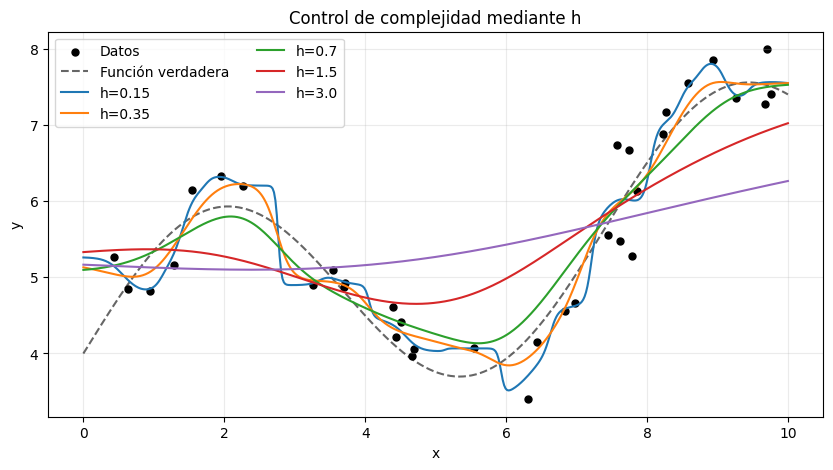

In [5]:
plt.figure(figsize=(10, 5))
plt.scatter(x, y, color="black", s=25, label="Datos")
plt.plot(malla, f_verdadera(malla), "k--", alpha=0.6, label="Función verdadera")
for h in [0.15, 0.35, 0.7, 1.5, 3.0]:
    plt.plot(malla, regresion_kernel(x, y, malla, h), label=f"h={h}")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Control de complejidad mediante h")
plt.legend(ncol=2); plt.grid(alpha=0.25); plt.show()

## 6. ¿Qué puntos contribuyen a una predicción?
Para $x_0=6.64$ y $h=0.70$, representamos los pesos **normalizados** y la curva de regresión. Los puntos cercanos a $x_0$ tienen más influencia.

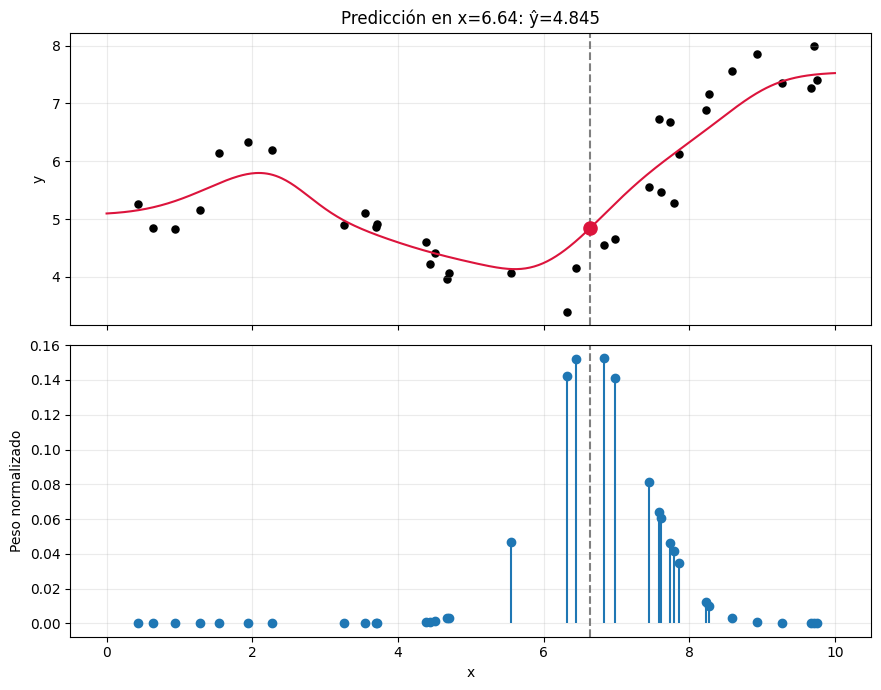

Suma de pesos normalizados: 1.0
Promedio ponderado: 4.844972093323904


In [6]:
x0, h_demo = 6.64, 0.70
pesos = kernel_gaussiano(x0 - x, h_demo)
alpha = pesos / pesos.sum()
pred = regresion_kernel(x, y, x0, h_demo)[0]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax1.scatter(x, y, color="black", s=26)
ax1.plot(malla, regresion_kernel(x, y, malla, h_demo), color="crimson")
ax1.scatter([x0], [pred], color="crimson", s=90, zorder=5)
ax1.axvline(x0, color="gray", ls="--")
ax1.set_ylabel("y"); ax1.set_title(f"Predicción en x={x0}: ŷ={pred:.3f}")
ax2.stem(x, alpha, basefmt=" ")
ax2.axvline(x0, color="gray", ls="--")
ax2.set_xlabel("x"); ax2.set_ylabel("Peso normalizado")
for ax in (ax1, ax2): ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()
print("Suma de pesos normalizados:", alpha.sum())
print("Promedio ponderado:", np.dot(alpha, y))

## 7. Conexión con mínimos cuadrados ponderados
Para un punto fijo $x$, consideremos el objetivo
$$J(a;x)=\sum_{i=1}^n K_h(x-x_i)(y_i-a)^2.$$
Derivando respecto a $a$:
$$\frac{\partial J}{\partial a}=-2\sum_i K_h(x-x_i)(y_i-a)=0.$$
Reordenando:
$$a\sum_i K_h(x-x_i)=\sum_i K_h(x-x_i)y_i.$$
Así obtenemos $a=\hat f_h(x)$. La segunda derivada es $2\sum_iK_h(x-x_i)>0$, por lo que es un mínimo. **La regresión por kernels es una minimización local de mínimos cuadrados ponderados.**

## 8. Validación cruzada dejando uno fuera (LOOCV)
Para cada $i$:
1. Excluimos la observación $(x_i,y_i)$.
2. Entrenamos conceptualmente con las otras $n-1$ observaciones.
3. Predecimos en $x_i$ y medimos $(y_i-\hat f_{-i,h}(x_i))^2$.
4. Promediamos los $n$ errores:
$$\boxed{CV(h)=\frac1n\sum_{i=1}^n[y_i-\hat f_{-i,h}(x_i)]^2}.$$
Elegimos $h^*=\arg\min_{h>0}CV(h)$ dentro de una malla de candidatos.

**Muy importante:** no se debe incluir el propio punto $i$ en su predicción LOOCV; hacerlo daría un error artificialmente optimista para $h$ pequeños.

h óptimo LOOCV = 0.2863
Error LOOCV mínimo = 0.18327


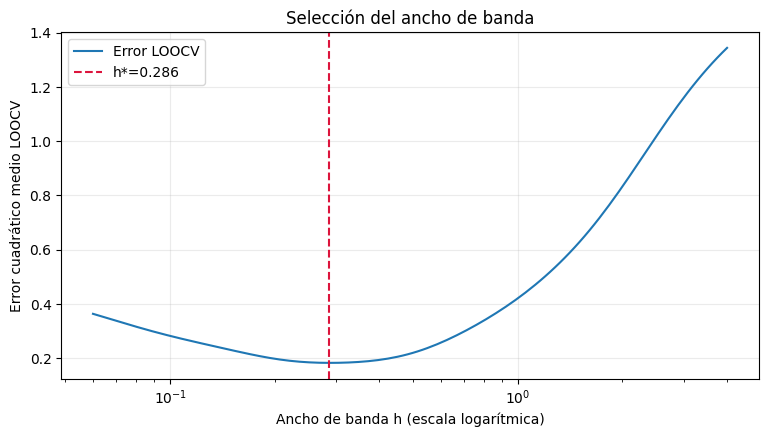

In [7]:
def error_loocv(x, y, h):
    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()
    if len(x) < 2:
        raise ValueError("Se necesitan al menos dos observaciones")
    errores = np.empty(len(x))
    for i in range(len(x)):
        mascara = np.arange(len(x)) != i
        pred_i = regresion_kernel(x[mascara], y[mascara], x[i], h)[0]
        errores[i] = (y[i] - pred_i)**2
    return errores.mean()

h_valores = np.geomspace(0.06, 4.0, 130)
errores_cv = np.array([error_loocv(x, y, h) for h in h_valores])
h_optimo = h_valores[np.argmin(errores_cv)]
print(f"h óptimo LOOCV = {h_optimo:.4f}")
print(f"Error LOOCV mínimo = {errores_cv.min():.5f}")

plt.figure(figsize=(9, 4.5))
plt.semilogx(h_valores, errores_cv, label="Error LOOCV")
plt.axvline(h_optimo, color="crimson", ls="--", label=f"h*={h_optimo:.3f}")
plt.xlabel("Ancho de banda h (escala logarítmica)")
plt.ylabel("Error cuadrático medio LOOCV")
plt.title("Selección del ancho de banda"); plt.grid(alpha=0.25); plt.legend(); plt.show()

## 9. Error de entrenamiento frente a error LOOCV
El error de entrenamiento usa los mismos datos para predecir y evaluar:
$$MSE_{\mathrm{train}}(h)=\frac1n\sum_i(y_i-\hat f_h(x_i))^2.$$
En cambio, LOOCV excluye cada observación al evaluarla. La separación entre ambas curvas ayuda a identificar sobreajuste.

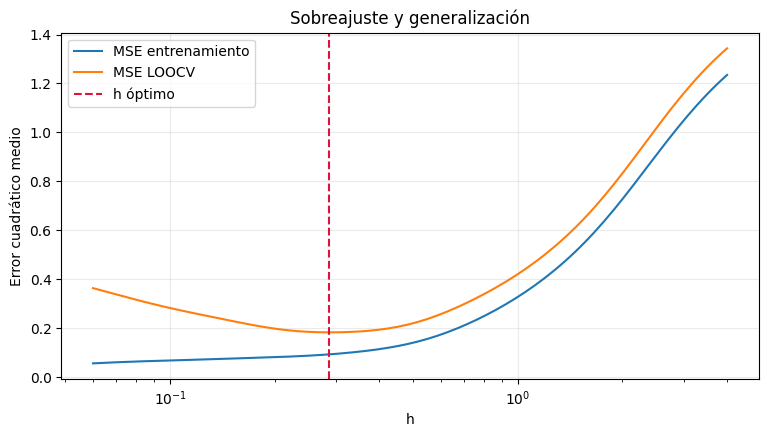

In [8]:
def mse_entrenamiento(x, y, h):
    pred = regresion_kernel(x, y, x, h)
    return np.mean((y - pred)**2)

errores_train = np.array([mse_entrenamiento(x, y, h) for h in h_valores])
plt.figure(figsize=(9, 4.5))
plt.semilogx(h_valores, errores_train, label="MSE entrenamiento")
plt.semilogx(h_valores, errores_cv, label="MSE LOOCV")
plt.axvline(h_optimo, color="crimson", ls="--", label="h óptimo")
plt.xlabel("h"); plt.ylabel("Error cuadrático medio")
plt.title("Sobreajuste y generalización"); plt.grid(alpha=0.25); plt.legend(); plt.show()

## 10. Grados de libertad efectivos
Para los puntos de entrenamiento, $\hat{\mathbf y}=S_h\mathbf y$, donde
$$ (S_h)_{ij}=\frac{K_h(x_i-x_j)}{\sum_k K_h(x_i-x_k)}.$$
Los **grados de libertad efectivos** del suavizador lineal son
$$df_{\mathrm{eff}}=\operatorname{tr}(S_h).$$
Si los $x_i$ son distintos: cuando $h\to0$, $S_h\to I$ y $df_{\mathrm{eff}}\to n$; cuando $h\to\infty$, $S_h\to\mathbf{1}\mathbf{1}^{T}/n$ y $df_{\mathrm{eff}}\to1$.
Esta medida cuantifica cómo $h$ controla la flexibilidad del modelo.

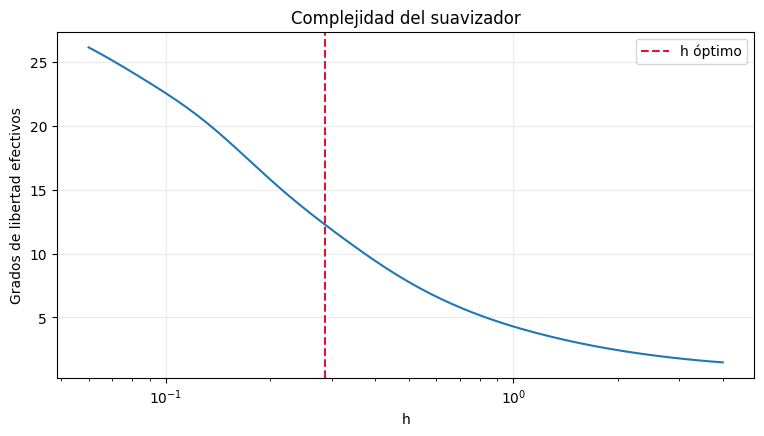

df efectivo en h*: 12.288646654185651


In [9]:
def matriz_suavizado(x, h):
    x = np.asarray(x, dtype=float).ravel()
    expo = -0.5 * ((x[:, None] - x[None, :]) / h)**2
    expo -= expo.max(axis=1, keepdims=True)
    w = np.exp(expo)
    return w / w.sum(axis=1, keepdims=True)

grados = np.array([np.trace(matriz_suavizado(x, h)) for h in h_valores])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogx(h_valores, grados)
ax.axvline(h_optimo, color="crimson", ls="--", label="h óptimo")
ax.set(xlabel="h", ylabel="Grados de libertad efectivos", title="Complejidad del suavizador")
ax.grid(alpha=0.25); ax.legend(); plt.show()
print("df efectivo en h*:", np.trace(matriz_suavizado(x, h_optimo)))

## 11. Curva final y comprobación con la función verdadera
En una simulación conocemos $f(x)$ y podemos comparar la curva estimada con ella. **En datos reales, la función verdadera es desconocida**; por eso usamos validación cruzada o un conjunto de prueba independiente.

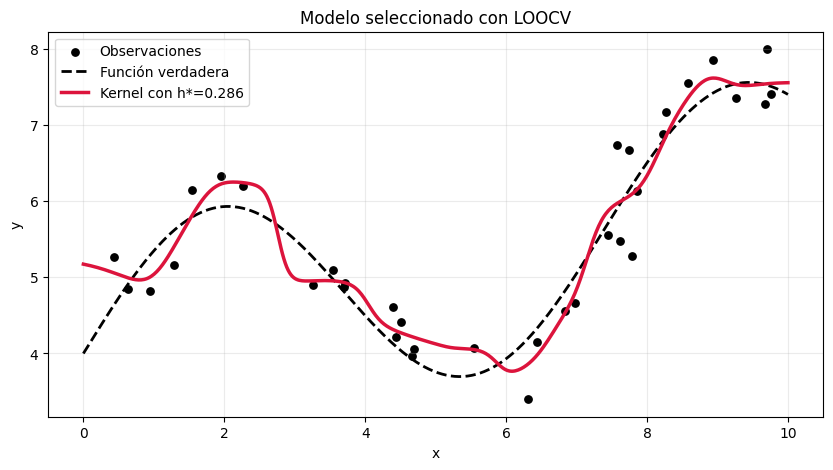

Error frente a f verdadera en la malla (solo simulación): 0.08672


In [10]:
plt.figure(figsize=(10, 5))
plt.scatter(x, y, color="black", s=28, label="Observaciones")
plt.plot(malla, f_verdadera(malla), "k--", lw=2, label="Función verdadera")
plt.plot(malla, regresion_kernel(x, y, malla, h_optimo),
         color="crimson", lw=2.5, label=f"Kernel con h*={h_optimo:.3f}")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Modelo seleccionado con LOOCV")
plt.grid(alpha=0.25); plt.legend(); plt.show()
mse_funcion = np.mean((regresion_kernel(x, y, malla, h_optimo)-f_verdadera(malla))**2)
print(f"Error frente a f verdadera en la malla (solo simulación): {mse_funcion:.5f}")

## 12. Verificación: LOOCV vectorizado sin bucles sobre observaciones
La matriz $S_h$ contiene los pesos normalizados con **todos** los puntos. Para excluir $i$, anulamos la diagonal y renormalizamos por fila. Esta implementación da el mismo resultado que el bucle explícito; es útil para comprobar la lógica y acelerar el cálculo.

La fórmula $\hat y_{-i}=(\hat y_i-S_{ii}y_i)/(1-S_{ii})$ es equivalente, pero puede sufrir cancelación numérica cuando $S_{ii}\approx1$. Por eso aquí anulamos la diagonal **antes de normalizar**.

In [11]:
def error_loocv_vectorizado(x, y, h):
    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()
    expo = -0.5 * ((x[:, None] - x[None, :]) / h)**2
    np.fill_diagonal(expo, -np.inf)
    expo -= np.max(expo, axis=1, keepdims=True)
    w = np.exp(expo)
    pred = (w @ y) / w.sum(axis=1)
    return np.mean((y - pred)**2)

for h in [0.1, 0.7, h_optimo, 2.0]:
    e1 = error_loocv(x, y, h)
    e2 = error_loocv_vectorizado(x, y, h)
    print(f"h={h:.3f}: bucle={e1:.8f}, vectorizado={e2:.8f}")
    assert np.isclose(e1, e2)

h=0.100: bucle=0.28259967, vectorizado=0.28259967
h=0.700: bucle=0.29837203, vectorizado=0.29837203
h=0.286: bucle=0.18326964, vectorizado=0.18326964
h=2.000: bucle=0.83288530, vectorizado=0.83288530


## 13. Exploración interactiva (opcional)
Si `ipywidgets` está disponible, cambia $x_0$ y $h$ y observa la predicción y los pesos. Si no está instalado, las demás celdas funcionan sin él.

In [13]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    def explorar(x0=6.64, h=0.7):
        pred = regresion_kernel(x, y, x0, h)[0]
        pesos = kernel_gaussiano(x0 - x, h)
        pesos = pesos / pesos.sum()
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
        ax1.scatter(x, y, color="black")
        ax1.plot(malla, regresion_kernel(x, y, malla, h), color="crimson")
        ax1.scatter([x0], [pred], color="crimson", s=80)
        ax1.axvline(x0, color="gray", ls="--")
        ax1.set_title(f"h={h:.2f}, x0={x0:.2f}, predicción={pred:.3f}")
        ax2.stem(x, pesos, basefmt=" ")
        ax2.axvline(x0, color="gray", ls="--")
        ax2.set(xlabel="x", ylabel="Peso normalizado")
        for a in (ax1, ax2): a.grid(alpha=0.2)
        plt.tight_layout(); plt.show()

    display(widgets.interactive(
        explorar,
        x0=widgets.FloatSlider(value=6.64, min=0, max=10, step=0.1),
        h=widgets.FloatLogSlider(value=0.7, base=10, min=-1.2, max=0.6, step=0.05)
    ))
except ImportError:
    print("Para la parte interactiva instala ipywidgets. El resto funciona normalmente.")

interactive(children=(FloatSlider(value=6.64, description='x0', max=10.0), FloatLogSlider(value=0.7, descripti…

## 14. Actividades propuestas
1. **Cálculo manual:** con los cuatro datos del apartado 2, calcula $\hat y(2.5)$ para $h=0.5$ y $h=2$. Explica el cambio.
2. **Sobreajuste:** grafica el error de entrenamiento y LOOCV para $h\in[0.05,5]$. ¿Dónde aparece la mayor diferencia?
3. **Ruido:** repite la simulación con $\sigma=0.2$ y $\sigma=1.2$. ¿Cómo cambia el $h^*$ elegido?
4. **Tamaño muestral:** repite con $n=15,35,100$. ¿Qué observas en la curva y el ancho de banda óptimo?
5. **Complejidad:** calcula $\operatorname{tr}(S_h)$ para tres valores de $h$. Relaciona el resultado con el sobreajuste.
6. **Reflexión:** ¿por qué el error de entrenamiento no es un criterio adecuado para seleccionar $h$?
7. **Reto:** implementa validación cruzada de cinco particiones (*5-fold*) y compara el $h$ elegido con LOOCV.

### Observaciones metodológicas
- LOOCV estima el error de predicción, pero **no garantiza** que el ancho de banda seleccionado sea el óptimo poblacional.
- Para evaluar el desempeño final de manera imparcial, conserva un **conjunto de prueba independiente** no utilizado al elegir $h$.
- La regresión de Nadaraya–Watson con kernel gaussiano puede presentar **sesgo en los bordes** del dominio; la regresión polinómica local es una alternativa.
- Los datos simulados aquí son reproducibles gracias a la semilla aleatoria.
